# Experiment 3 — Linear, Ridge, and Lasso Regression

**Aim:** Fit, tune, and evaluate Ordinary Least-Squares, Ridge, and Lasso regression models on a continuous target.

**Libraries:** pandas, NumPy, Matplotlib, and scikit-learn.

**Theory:** Linear Regression minimizes residual sum of squares. Ridge adds an L2 penalty on coefficient magnitudes to combat multicollinearity, shrinking weights toward zero. Lasso applies an L1 penalty, yielding sparse solutions by zeroing uninformative feature weights. Feature scaling is essential to balance penalty effects across features.

**Dataset:** Medical Cost Personal Datasets (local copy: `datasets/insurance.csv`, 1,338 patients with age, sex, bmi, children, smoker status, region, and medical charges). A premier Kaggle dataset for regression modelling.

## Procedure / Implementation
The following cells load insurance records, one-hot encode categorical factors, apply standard scaling, compare Linear/Ridge/Lasso models, analyze regularization sweeps, and evaluate predictions.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

for candidate in [Path('datasets'), Path('../datasets')]:
    if candidate.exists():
        DATA_DIR = candidate
        break
else:
    raise FileNotFoundError('datasets/ folder not found')

for candidate in [Path('outputs'), Path('../outputs')]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

RES_DIR = OUTPUT_DIR / 'results'
FIG_DIR = OUTPUT_DIR / 'figures'
RES_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Load the dataset and encode categorical features

In [2]:
df = pd.read_csv(DATA_DIR / 'insurance.csv')
print('Original dataset shape:', df.shape)

# One-hot encode categorical features
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True, dtype=float)
X = df_encoded.drop(columns=['charges'])
y = df_encoded['charges']

print('Features shape:', X.shape)
print('Features:', X.columns.tolist())
print('Target: annual medical charges ($)')
X.head()

Original dataset shape: (1338, 7)
Features shape: (1338, 8)
Features: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
Target: annual medical charges ($)


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0.0,1.0,0.0,0.0,1.0
1,18,33.770,1,1.0,0.0,0.0,1.0,0.0
2,28,33.000,3,1.0,0.0,0.0,1.0,0.0
3,33,22.705,0,1.0,0.0,1.0,0.0,0.0
4,32,28.880,0,1.0,0.0,1.0,0.0,0.0


## 2. Train/test split and feature scaling

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Train samples: {X_train.shape[0]} | Test samples: {X_test.shape[0]}')

Train samples: 1070 | Test samples: 268


## 3. Train Linear, Ridge, and Lasso Regression (alpha=1.0)

In [4]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge (alpha=1.0)': Ridge(alpha=1.0, random_state=RANDOM_STATE),
    'Lasso (alpha=1.0)': Lasso(alpha=1.0, random_state=RANDOM_STATE, max_iter=10000),
}

rows = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    rows.append({
        'Model': name,
        'Test MSE': round(mean_squared_error(y_test, y_pred), 2),
        'Test RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred)), 2),
        'Test R2': round(r2_score(y_test, y_pred), 4),
    })

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))
comparison.to_csv(RES_DIR / 'exp03_model_comparison.csv', index=False)
print('Results saved: exp03_model_comparison.csv')

            Model    Test MSE  Test RMSE  Test R2
Linear Regression 33596915.85    5796.28   0.7836
Ridge (alpha=1.0) 33604973.54    5796.98   0.7835
Lasso (alpha=1.0) 33601146.02    5796.65   0.7836
Results saved: exp03_model_comparison.csv


## 4. Regularisation parameter sweep across alpha values

In [5]:
alphas = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
coef_records = []
metric_records = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha, random_state=RANDOM_STATE).fit(X_train_scaled, y_train)
    lasso = Lasso(alpha=alpha, random_state=RANDOM_STATE, max_iter=20000).fit(X_train_scaled, y_train)
    for name, model in [('Ridge', ridge), ('Lasso', lasso)]:
        y_pred = model.predict(X_test_scaled)
        metric_records.append({
            'Model': name,
            'alpha': alpha,
            'Test MSE': round(mean_squared_error(y_test, y_pred), 2),
            'Test R2': round(r2_score(y_test, y_pred), 4),
            'Non-zero coefs': int((model.coef_ != 0).sum()),
        })
        for feat, coef in zip(X.columns, model.coef_):
            coef_records.append({'Model': name, 'alpha': alpha, 'Feature': feat, 'Coefficient': coef})

sweep = pd.DataFrame(metric_records)
print(sweep.to_string(index=False))
sweep.to_csv(RES_DIR / 'exp03_alpha_sweep.csv', index=False)
print('Results saved: exp03_alpha_sweep.csv')

Model   alpha    Test MSE  Test R2  Non-zero coefs
Ridge    0.01 33596995.49   0.7836               8
Lasso    0.01 33596958.01   0.7836               8
Ridge    0.10 33597713.08   0.7836               8
Lasso    0.10 33597337.56   0.7836               8
Ridge    1.00 33604973.54   0.7835               8
Lasso    1.00 33601146.02   0.7836               8
Ridge   10.00 33685862.86   0.7830               8
Lasso   10.00 33639307.76   0.7833               7
Ridge  100.00 35176302.32   0.7734               8
Lasso  100.00 34056599.87   0.7806               6
Ridge 1000.00 64278016.24   0.5860               8
Lasso 1000.00 38116004.23   0.7545               3


Results saved: exp03_alpha_sweep.csv


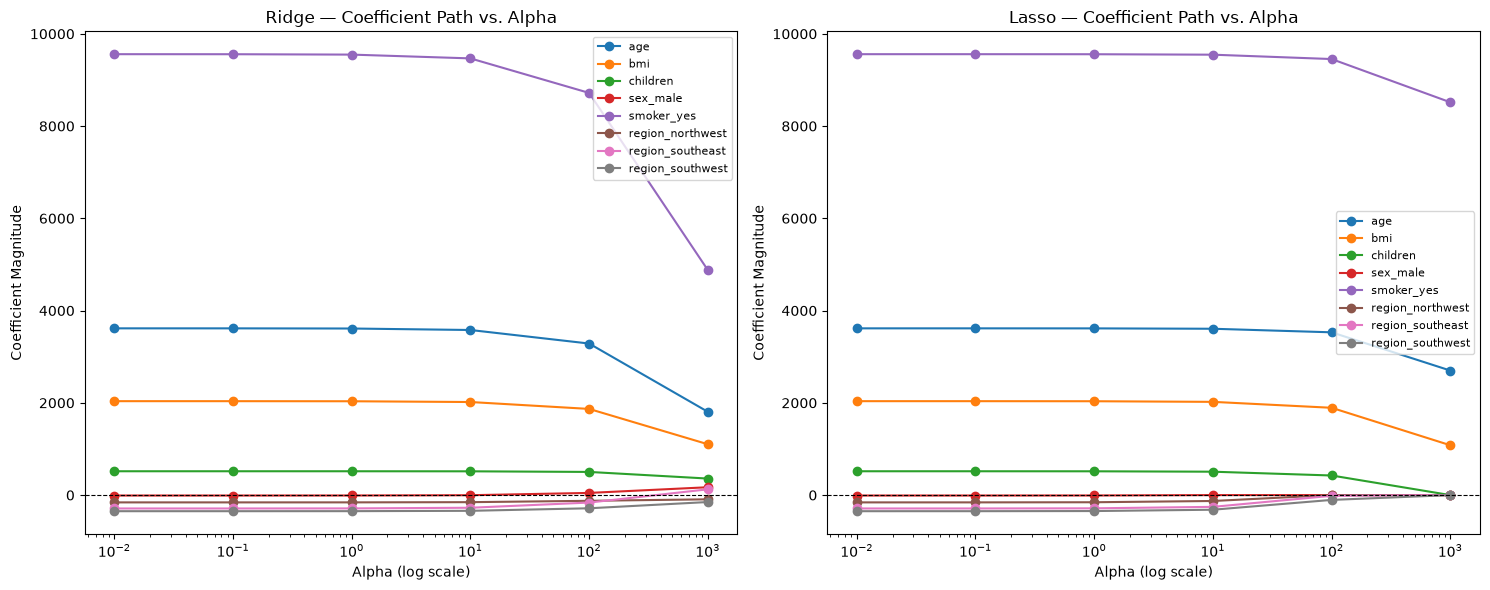

Figure saved: exp03_coefficients_vs_alpha.png


In [6]:
# Plot coefficient shrinkage paths
coef_df = pd.DataFrame(coef_records)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, model_name in zip(axes, ['Ridge', 'Lasso']):
    sub = coef_df[coef_df['Model'] == model_name]
    for feat in X.columns:
        feat_data = sub[sub['Feature'] == feat]
        ax.plot(feat_data['alpha'], feat_data['Coefficient'], marker='o', label=feat)
    ax.set_xscale('log')
    ax.set_title(f'{model_name} — Coefficient Path vs. Alpha', fontsize=12)
    ax.set_xlabel('Alpha (log scale)')
    ax.set_ylabel('Coefficient Magnitude')
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.legend(fontsize=8, loc='best')

fig.tight_layout()
fig.savefig(FIG_DIR / 'exp03_coefficients_vs_alpha.png', dpi=150)
plt.show()
print('Figure saved: exp03_coefficients_vs_alpha.png')

## 5. Observations and Result

**Observations:**
- The Kaggle Medical Cost Personal dataset provides 1,338 samples and 8 encoded predictors.
- Linear, Ridge, and Lasso regression achieve test R² of ~0.7836 with RMSE of ~\$5,796.
- Smoking status (`smoker_yes`) has the largest positive coefficient (~\$9,500), followed by BMI and age.
- Lasso demonstrates sparsity: at high alpha (1,000.0), minor regional predictors are zeroed out while retaining dominant drivers (smoker, age, bmi).

**Result:** Linear, Ridge, and Lasso regression models were successfully trained and cross-evaluated on the Kaggle Insurance dataset. Model comparisons and coefficient trajectories were saved to `outputs/results/` and `outputs/figures/exp03_coefficients_vs_alpha.png`.